# 4b. Training a small encoder on transcripts (PyTorch)

Notebook 04a used one attention head on hand-made mini-transcripts. Now we train a real (if tiny) **encoder**
on the full transcripts of notebook 01, with the objective that made BERT famous: **masked-token prediction**.
Some codons are hidden behind `[MASK]`; the model must guess them from everything around them.

| Item | Value |
|---|---|
| Input | `[CLS]` + transcript (RNA codons) + `[EOS]` |
| Vocabulary | 64 RNA codons + `[PAD]`, `[MASK]`, `[CLS]`, `[EOS]` |
| Size | d_model 32, 2 heads, feed-forward 64, 2 layers (≈30k parameters) |
| Objective | 15% of the codons masked; loss on the masked positions only |
| Training | AdamW, learning rate 1e-3, batch 32, 30 epochs; split by genome 80/20 |

Three configurations, each trained from the same seed and exported for Lab C:

- `full` — learned positional embeddings, bidirectional attention;
- `no_position` — no positional embeddings;
- `causal` — positions, but each token may only look **left** (like a decoder).

This notebook only trains and exports. What the vectors have learned — and whether attention is doing the
work — is tested with probes in notebook 04c. **A low masked-token loss is not evidence that attention does the
work**: with strong codon dialects, many masked codons are guessable from their neighbours alone.

Lab C re-runs the forward pass of these weights in JavaScript; a parity test file checks that the browser
gets the same numbers.

*Run from `04-attention/`, after notebook 01 (it reads `data/corpus/transcripts.csv`).*

In [1]:
import sys, os, json, math, time, inspect
from datetime import datetime, timezone

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F

sys.path.insert(0, "..")
import protocell_lang as L

# ------------------------------------------------------------
# Configuration (design-spec §4.7)
# ------------------------------------------------------------
SEED = 42
D_MODEL, N_HEADS, D_FF, N_LAYERS = 32, 2, 64, 2
MAX_LEN = 256
MASK_RATE = 0.15
LEARNING_RATE = 1e-3
BATCH_SIZE = 32
EPOCHS = 30
SNAPSHOT_EPOCHS = [0, 1, 2, 3, 5, 8, 12, 18, 24, 30]
LN_EPS = 1e-5
CONFIGS = {"full": {"causal": False, "use_position": True},
           "no_position": {"causal": False, "use_position": False},
           "causal": {"causal": True, "use_position": True}}

INPUT_FILE = "../data/corpus/transcripts.csv"
WEB_DIR = "../data/web"
NOTEBOOK = "04-attention/04b_encoder_training.ipynb"

torch.set_num_threads(min(4, os.cpu_count() or 1))
torch.use_deterministic_algorithms(True)
print("PyTorch", torch.__version__, "· threads", torch.get_num_threads())

PyTorch 2.15.0+cpu · threads 4


## 1. Data: transcripts as token sequences

The vocabulary starts with the four special tokens, followed by the 64 RNA codons. Genomes — not transcripts —
are split 80/20, because the transcripts of one genome share almost all of their sequence (design-spec §2.5).

In [2]:
SPECIALS = ["[PAD]", "[MASK]", "[CLS]", "[EOS]"]
PAD, MASK, CLS, EOS = range(4)
VOCABULARY = SPECIALS + [L.transcribe(c) for c in L.ALL_CODONS]
TOKEN_ID = {t: i for i, t in enumerate(VOCABULARY)}

frame = pd.read_csv(INPUT_FILE).sort_values(["transcript_id", "position"])
transcripts = []
for tid, group in frame.groupby("transcript_id"):
    transcripts.append({
        "transcript_id": int(tid), "genome_id": int(group["genome_id"].iloc[0]),
        "condition": group["condition"].iloc[0],
        "ids": [CLS] + [TOKEN_ID[c] for c in group["codon"]] + [EOS],
        "start_roles": set(group["start_role"].dropna()),
    })

genomes = np.random.default_rng(SEED).permutation(sorted({t["genome_id"] for t in transcripts}))
test_genomes = sorted(int(g) for g in genomes[: len(genomes) // 5])
train_genomes = sorted(int(g) for g in genomes[len(genomes) // 5:])
train = [t for t in transcripts if t["genome_id"] in set(train_genomes)]
test = [t for t in transcripts if t["genome_id"] in set(test_genomes)]
lengths = [len(t["ids"]) for t in transcripts]
print(f"{len(train)} training and {len(test)} test transcripts ({len(train_genomes)} / {len(test_genomes)} genomes)")
print(f"sequence length (with [CLS] and [EOS]): {min(lengths)}–{max(lengths)}, max allowed {MAX_LEN}")

1280 training and 320 test transcripts (320 / 80 genomes)
sequence length (with [CLS] and [EOS]): 45–223, max allowed 256


## 2. Masking

In every sequence, 15% of the codon tokens (at least one) are replaced by `[MASK]`; special tokens are never
masked. The model sees the masked sequence and is scored only on the hidden positions. During training the
masks change every epoch; for measuring, each set (training and test) gets one fixed set of masks, so that
numbers from different epochs are comparable.

In [3]:
def pad_batch(sequences):
    longest = max(len(s) for s in sequences)
    ids = torch.full((len(sequences), longest), PAD, dtype=torch.long)
    for i, s in enumerate(sequences):
        ids[i, :len(s)] = torch.tensor(s)
    return ids


def mask_tokens(ids, generator):
    # Returns (masked input, targets); targets are -100 (ignored) except at masked positions.
    inputs, targets = ids.clone(), torch.full_like(ids, -100)
    for i in range(len(ids)):
        codon_positions = torch.nonzero(ids[i] >= len(SPECIALS)).flatten()
        k = max(1, math.ceil(MASK_RATE * len(codon_positions)))
        chosen = codon_positions[torch.randperm(len(codon_positions), generator=generator)[:k]]
        targets[i, chosen] = ids[i, chosen]
        inputs[i, chosen] = MASK
    return inputs, targets


example = pad_batch([test[0]["ids"]])
masked, target = mask_tokens(example, torch.Generator().manual_seed(SEED))
show = lambda row: " ".join(VOCABULARY[i] for i in row[:14])
print("original:", show(example[0]), "…")
print("masked:  ", show(masked[0]), "…")

original: [CLS] WXV WXX WXX WXW VWX YXX WXV WWX XVX XYX YVY XWX XXX …
masked:   [CLS] WXV WXX WXX WXW VWX YXX WXV WWX XVX XYX [MASK] XWX XXX …


## 3. The model, written out

Each block is **pre-LayerNorm**: $x \leftarrow x + \mathrm{Attn}(\mathrm{LN}(x))$, then
$x \leftarrow x + \mathrm{FF}(\mathrm{LN}(x))$ with a ReLU feed-forward layer.

Attention is written explicitly (no `nn.MultiheadAttention`): one linear layer produces $Q, K, V$ (32 numbers
each), they are split into 2 heads of 16, each head computes $\mathrm{softmax}(QK^\top/\sqrt{16})\,V$, and an
output layer mixes the heads. Two masks can block a score before the softmax:

- **padding** — nobody attends to `[PAD]`;
- **causal** (only in the `causal` configuration) — token $i$ cannot see tokens $j > i$.

There is no dropout, so the same weights always give the same numbers — in PyTorch and in the browser.

In [4]:
class SelfAttention(nn.Module):
    def __init__(self, d_model, n_heads, causal):
        super().__init__()
        self.n_heads, self.causal = n_heads, causal
        self.qkv = nn.Linear(d_model, 3 * d_model)      # Q, K and V in one matrix
        self.out = nn.Linear(d_model, d_model)          # mixes the heads

    def forward(self, x, real):
        # x: (batch, length, d_model); real: (batch, length), True for tokens that are not [PAD]
        batch, length, d_model = x.shape
        d_head = d_model // self.n_heads
        q, k, v = self.qkv(x).split(d_model, dim=-1)
        split = lambda t: t.view(batch, length, self.n_heads, d_head).transpose(1, 2)   # → (batch, head, length, d_head)
        q, k, v = split(q), split(k), split(v)
        scores = q @ k.transpose(-2, -1) / math.sqrt(d_head)                           # (batch, head, query, key)
        allowed = real[:, None, None, :]
        if self.causal:
            allowed = allowed & torch.ones(length, length, dtype=torch.bool).tril()
        weights = torch.softmax(scores.masked_fill(~allowed, float("-inf")), dim=-1)
        mixed = (weights @ v).transpose(1, 2).reshape(batch, length, d_model)
        return self.out(mixed), weights


class Block(nn.Module):
    def __init__(self, d_model, n_heads, d_ff, causal):
        super().__init__()
        self.ln1 = nn.LayerNorm(d_model, eps=LN_EPS)
        self.attn = SelfAttention(d_model, n_heads, causal)
        self.ln2 = nn.LayerNorm(d_model, eps=LN_EPS)
        self.ff1 = nn.Linear(d_model, d_ff)
        self.ff2 = nn.Linear(d_ff, d_model)

    def forward(self, x, real):
        attended, weights = self.attn(self.ln1(x), real)
        x = x + attended
        x = x + self.ff2(torch.relu(self.ff1(self.ln2(x))))
        return x, weights


class Encoder(nn.Module):
    def __init__(self, causal, use_position):
        super().__init__()
        self.use_position = use_position
        self.tok_emb = nn.Embedding(len(VOCABULARY), D_MODEL)
        if use_position:
            self.pos_emb = nn.Embedding(MAX_LEN, D_MODEL)
        self.blocks = nn.ModuleList([Block(D_MODEL, N_HEADS, D_FF, causal) for _ in range(N_LAYERS)])
        self.ln_final = nn.LayerNorm(D_MODEL, eps=LN_EPS)
        self.head = nn.Linear(D_MODEL, len(VOCABULARY))   # masked-token prediction

    def forward(self, ids):
        real = ids != PAD
        x = self.tok_emb(ids)
        if self.use_position:
            x = x + self.pos_emb(torch.arange(ids.shape[1]))[None]
        attentions = []
        for block in self.blocks:
            x, weights = block(x, real)
            attentions.append(weights)
        final = self.ln_final(x)                       # the contextual vector of every token
        return self.head(final), final, attentions

In [5]:
model = Encoder(causal=False, use_position=True)
print(f"{sum(p.numel() for p in model.parameters()):,} parameters")
pd.DataFrame([(name, tuple(p.shape)) for name, p in model.state_dict().items()], columns=["tensor", "shape"])

29,764 parameters


,tensor,shape
0,tok_emb.weight,"(68, 32)"
1,pos_emb.weight,"(256, 32)"
2,blocks.0.ln1.weight,"(32,)"
3,blocks.0.ln1.bias,"(32,)"
4,blocks.0.attn.qkv.weight,"(96, 32)"
5,blocks.0.attn.qkv.bias,"(96,)"
6,blocks.0.attn.out.weight,"(32, 32)"
7,blocks.0.attn.out.bias,"(32,)"
8,blocks.0.ln2.weight,"(32,)"
9,blocks.0.ln2.bias,"(32,)"


## 4. Training

Each configuration is built after `torch.manual_seed(42)` and trained with AdamW. At the snapshot epochs
(0 — before any training — then 1, 2, 3, 5, 8, 12, 18, 24, 30) we measure masked-token loss and accuracy on
the training set (**training performance**) and on the test set, and store a copy of the weights.

In [6]:
def evaluate(model, dataset, masks):
    model.eval()
    total, correct, count = 0.0, 0, 0
    with torch.no_grad():
        for (inputs, targets) in masks:
            logits = model(inputs)[0]
            selected = targets != -100
            total += F.cross_entropy(logits[selected], targets[selected], reduction="sum").item()
            correct += (logits[selected].argmax(-1) == targets[selected]).sum().item()
            count += selected.sum().item()
    return total / count, correct / count


def fixed_masks(dataset, seed):
    generator = torch.Generator().manual_seed(seed)
    return [mask_tokens(pad_batch([t["ids"] for t in dataset[i:i + 64]]), generator) for i in range(0, len(dataset), 64)]


def train_config(name, causal, use_position):
    torch.manual_seed(SEED)
    model = Encoder(causal, use_position)
    optimizer = torch.optim.AdamW(model.parameters(), lr=LEARNING_RATE)
    order_generator = torch.Generator().manual_seed(SEED)
    mask_generator = torch.Generator().manual_seed(SEED + 1)
    train_masks, test_masks = fixed_masks(train, SEED + 2), fixed_masks(test, SEED + 3)
    snapshots, started = [], time.time()

    for epoch in range(EPOCHS + 1):
        if epoch > 0:
            model.train()
            order = torch.randperm(len(train), generator=order_generator).tolist()
            for start in range(0, len(order), BATCH_SIZE):
                ids = pad_batch([train[i]["ids"] for i in order[start:start + BATCH_SIZE]])
                inputs, targets = mask_tokens(ids, mask_generator)
                loss = F.cross_entropy(model(inputs)[0].reshape(-1, len(VOCABULARY)), targets.reshape(-1), ignore_index=-100)
                optimizer.zero_grad()
                loss.backward()
                optimizer.step()
        if epoch in SNAPSHOT_EPOCHS:
            train_loss, train_acc = evaluate(model, train, train_masks)
            test_loss, test_acc = evaluate(model, test, test_masks)
            snapshots.append({"epoch": epoch, "train_loss": train_loss, "train_masked_acc": train_acc,
                              "test_loss": test_loss, "masked_acc": test_acc,
                              "weights": {k: v.detach().clone() for k, v in model.state_dict().items()}})
            print(f"{name:12} epoch {epoch:2}: train loss {train_loss:.3f} acc {train_acc:.3f} · test loss {test_loss:.3f} acc {test_acc:.3f}")
    return model, snapshots, time.time() - started

In [7]:
results = {}
for name, options in CONFIGS.items():
    model, snapshots, seconds = train_config(name, **options)
    results[name] = {"model": model, "snapshots": snapshots, "seconds": seconds}
    print(f"→ {name}: {seconds:.0f} s\n")
print("Training time per configuration:", {n: f"{r['seconds']:.0f} s" for n, r in results.items()})

full         epoch  0: train loss 4.496 acc 0.006 · test loss 4.494 acc 0.006


full         epoch  1: train loss 3.603 acc 0.066 · test loss 3.612 acc 0.069


full         epoch  2: train loss 3.509 acc 0.079 · test loss 3.517 acc 0.083


full         epoch  3: train loss 3.493 acc 0.085 · test loss 3.505 acc 0.089


full         epoch  5: train loss 3.396 acc 0.109 · test loss 3.411 acc 0.118


full         epoch  8: train loss 3.192 acc 0.158 · test loss 3.208 acc 0.158


... (20 outputs left out)

causal       epoch 12: train loss 2.925 acc 0.212 · test loss 2.956 acc 0.202


causal       epoch 18: train loss 2.836 acc 0.230 · test loss 2.876 acc 0.227


causal       epoch 24: train loss 2.779 acc 0.243 · test loss 2.832 acc 0.231


causal       epoch 30: train loss 2.734 acc 0.249 · test loss 2.795 acc 0.244
→ causal: 101 s

Training time per configuration: {'full': '90 s', 'no_position': '95 s', 'causal': '101 s'}


### Learning curves

Masked-token loss and accuracy per snapshot. Chance accuracy is about 1/64 if the model knew nothing; always
guessing the most frequent codon would already do much better, because body codons dominate the transcripts.

Most-frequent-codon baseline (training set): 0.071


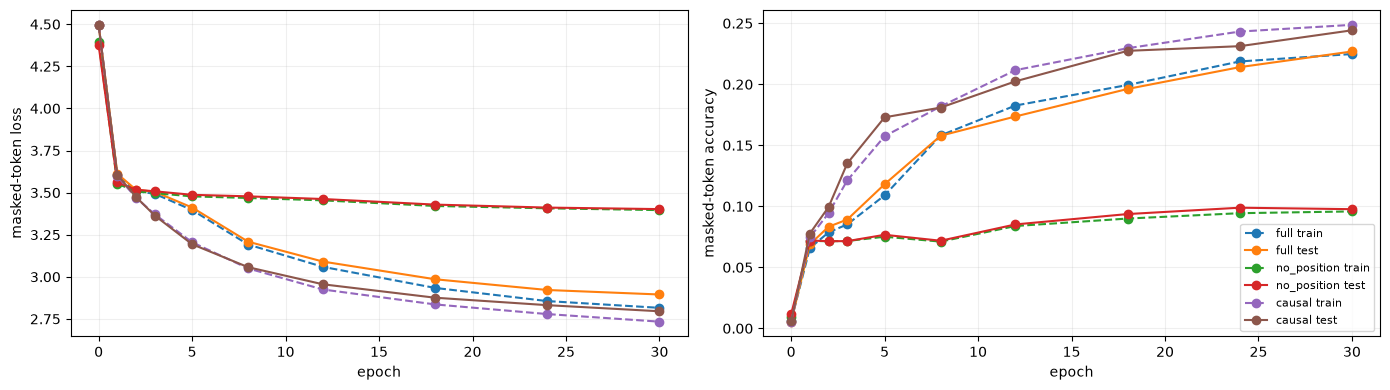

,full,no_position,causal
train acc (training performance),0.225,0.096,0.249
test acc,0.227,0.098,0.244
test loss,2.895,3.402,2.795
seconds,89.910,95.350,100.668


In [8]:
codon_counts = np.bincount([i for t in train for i in t["ids"] if i >= len(SPECIALS)], minlength=len(VOCABULARY))
print(f"Most-frequent-codon baseline (training set): {codon_counts.max() / codon_counts.sum():.3f}")

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
for name, r in results.items():
    epochs = [s["epoch"] for s in r["snapshots"]]
    for key, style in (("train", "--"), ("test", "-")):
        axes[0].plot(epochs, [s[f"{key}_loss"] for s in r["snapshots"]], style, marker="o", label=f"{name} {key}")
        axes[1].plot(epochs, [s["train_masked_acc" if key == "train" else "masked_acc"] for s in r["snapshots"]], style, marker="o", label=f"{name} {key}")
axes[0].set_ylabel("masked-token loss")
axes[1].set_ylabel("masked-token accuracy")
for ax in axes:
    ax.set_xlabel("epoch"); ax.grid(alpha=0.2)
axes[1].legend(fontsize=8)
fig.tight_layout()
plt.show()
pd.DataFrame({name: {"train acc (training performance)": r["snapshots"][-1]["train_masked_acc"], "test acc": r["snapshots"][-1]["masked_acc"],
                     "test loss": r["snapshots"][-1]["test_loss"], "seconds": r["seconds"]} for name, r in results.items()}).round(3)

### A first look at attention

Layer-0 attention of one short test transcript (`K_high`), both heads, for each configuration. In the
`causal` configuration everything above the diagonal is zero: a token cannot see what comes after it. These
pictures are descriptions, not evidence; the probes in 04c test what the vectors contain.

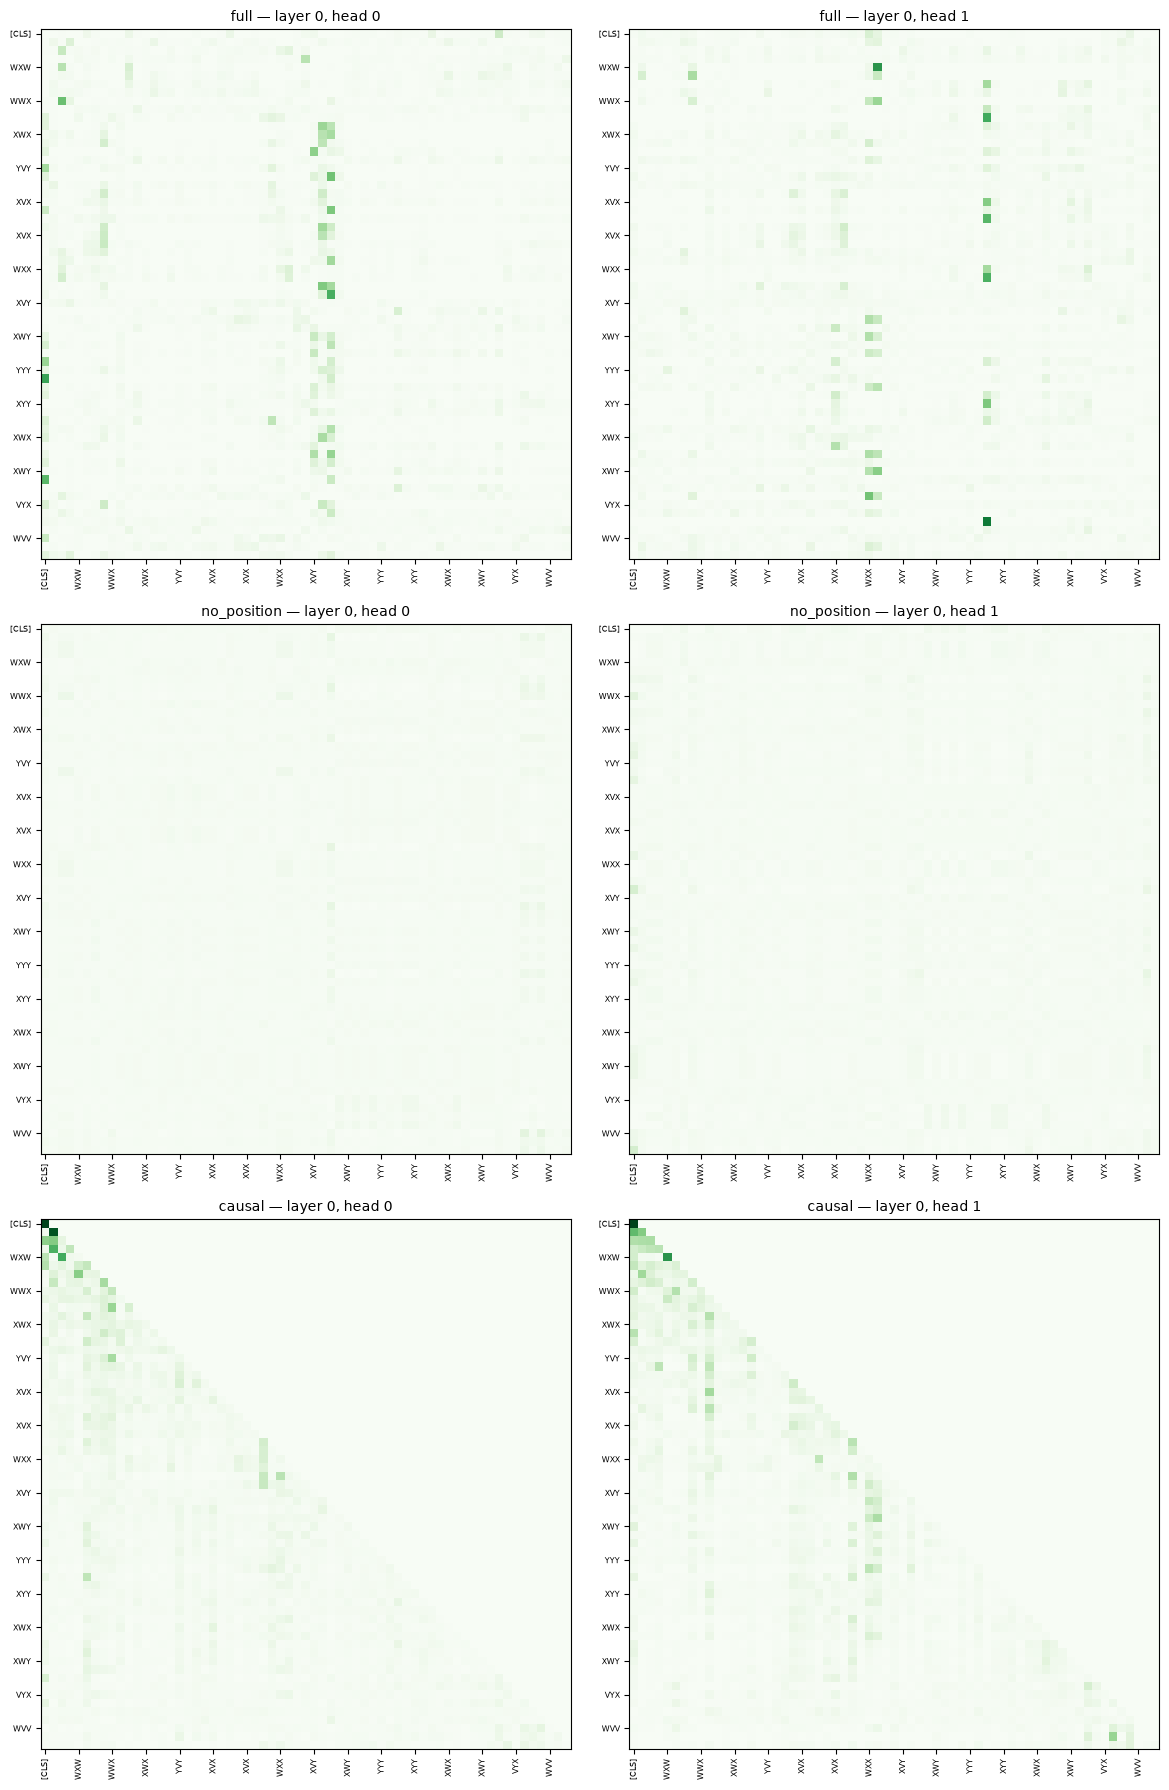

In [9]:
sample = next(t for t in test if t["condition"] == "K_high")
labels = [VOCABULARY[i] for i in sample["ids"]]
fig, axes = plt.subplots(len(results), N_HEADS, figsize=(12, 6 * len(results)))
for row, (name, r) in enumerate(results.items()):
    r["model"].eval()
    with torch.no_grad():
        attention = r["model"](torch.tensor([sample["ids"]]))[2][0][0]
    for head in range(N_HEADS):
        ax = axes[row, head]
        ax.imshow(attention[head], cmap="Greens", vmin=0, vmax=1)
        ax.set_title(f"{name} — layer 0, head {head}", fontsize=10)
        ax.set_xticks(range(len(labels))[::4], labels[::4], rotation=90, fontsize=6)
        ax.set_yticks(range(len(labels))[::4], labels[::4], fontsize=6)
fig.tight_layout()
plt.show()

### Observations (seed 42)

These are descriptions of training, not tests of the predictions; those come in 04c.

- **Training time:** about 1.5 minutes per configuration on a laptop CPU with 4 threads, so about 5 minutes
  for all three.
- **The `full` model:**
  - its masked-token accuracy rises from 0.006 (untrained) to **0.227** on the test set, and its training
    performance is 0.225;
  - the test and training numbers stay close, so it is not over-fitting;
  - the curves are **still improving at epoch 30** (test loss 2.92 → 2.90 between epochs 24 and 30), so the
    model is not fully converged.
- **The `no_position` model** reaches only **0.098**, little above the 0.071 of always guessing the most
  frequent codon. Without positions, every token in a transcript sees the same bag of tokens, so a masked
  codon's prediction can depend only on which codons are present, not on what is next to it.
- **The `causal` model** reaches **0.244**, slightly *higher* than `full`. Looking only to the left is not a
  handicap for this objective here: in this generator, the gene body to the left of a masked codon already
  says which dialect it is in. It is also a reminder of the caveat above. Masked-token accuracy measures
  guessing codons, not the three polysemy cases. Whether the bidirectional model's vectors carry the
  right-hand context (case 3) is a question for the probes in 04c.

## 5. Export for Lab C

Each configuration goes to its own file, with every snapshot's weights as named tensors (rounded to 6
decimals). Linear layers are stored as PyTorch stores them, `weight` with shape (out, in), so a layer computes
$y = xW^\top + b$ — the browser does exactly that.

The parity file holds four test transcripts per configuration with the expected final hidden states and the
layer-0 attention weights. The expected values are computed **from the rounded weights that were exported**,
in float64, so the browser compares against exactly the model it loads.

In [10]:
def rounded(tensor):
    return np.round(tensor.double().numpy(), 6)


def model_from_weights(weights, causal, use_position):
    # A float64 copy of the model with the exported (rounded) weights.
    model = Encoder(causal, use_position).double()
    model.load_state_dict({k: torch.tensor(v) for k, v in weights.items()})
    return model.eval()


def parity_cases():
    clean = lambda t: not (t["start_roles"] - {"true_start"})
    return [("K_low", next(t for t in test if t["condition"] == "K_low" and clean(t))),
            ("K_high", next(t for t in test if t["condition"] == "K_high" and clean(t))),
            ("broken RBS", next(t for t in test if t["condition"] == "K_high" and "false_start_broken_rbs" in t["start_roles"])),
            ("spacer decoy", next(t for t in test if t["condition"] == "K_high" and "false_start_spacer" in t["start_roles"]))]


def class_source(cls):
    # inspect cannot read a class defined in a notebook, but it can read its methods.
    methods = "\n".join(inspect.getsource(m) for m in (cls.__init__, cls.forward))
    return f"class {cls.__name__}(nn.Module):\n{methods}"


metadata = lambda: {
    "produced_by": NOTEBOOK, "function": train_config.__name__,
    "source": "\n\n".join([class_source(c) for c in (SelfAttention, Block, Encoder)] + [inspect.getsource(f) for f in (mask_tokens, train_config)]),
    "seed": SEED,
    "params": {"d_model": D_MODEL, "n_heads": N_HEADS, "d_ff": D_FF, "n_layers": N_LAYERS, "max_len": MAX_LEN,
               "mask_rate": MASK_RATE, "learning_rate": LEARNING_RATE, "batch_size": BATCH_SIZE, "epochs": EPOCHS,
               "snapshot_epochs": SNAPSHOT_EPOCHS, "optimizer": "AdamW (PyTorch defaults otherwise)", "dropout": 0},
    "generator_version": L.GENERATOR_VERSION,
    "created": datetime.now(timezone.utc).isoformat(timespec="seconds"),
}

parity, sizes = {}, {}
for name, r in results.items():
    options = CONFIGS[name]
    exported = [{**{k: s[k] for k in ("epoch", "train_loss", "train_masked_acc", "test_loss", "masked_acc")},
                 "weights": {k: rounded(v) for k, v in s["weights"].items()}} for s in r["snapshots"]]
    payload = {
        "metadata": metadata(),
        "config": {"name": name, **options, "d_model": D_MODEL, "n_heads": N_HEADS, "d_ff": D_FF, "n_layers": N_LAYERS,
                   "max_len": MAX_LEN, "layer_norm_eps": LN_EPS, "vocabulary": VOCABULARY,
                   "special_tokens": dict(zip(SPECIALS, range(4))),
                   "train_genomes": train_genomes, "test_genomes": test_genomes},
        "snapshots": [{**{k: v for k, v in s.items() if k != "weights"}, "weights": {k: v.tolist() for k, v in s["weights"].items()}}
                      for s in exported],
    }
    path = f"{WEB_DIR}/encoder-{name}.json"
    with open(path, "w", encoding="utf-8") as f:
        json.dump(payload, f, separators=(",", ":"))
    sizes[path] = os.path.getsize(path)

    final = model_from_weights(exported[-1]["weights"], **options)
    tests = []
    for label, t in parity_cases():
        with torch.no_grad():
            _, hidden, attentions = final(torch.tensor([t["ids"]]))
        tests.append({"label": label, "transcript_id": t["transcript_id"], "ids": t["ids"],
                      "final": np.round(hidden[0].numpy(), 7).tolist(),
                      "attention_layer0": np.round(attentions[0][0].numpy(), 7).tolist()})
    parity[name] = {"epoch": exported[-1]["epoch"], "tests": tests}

parity_payload = {"metadata": {**metadata(), "function": "parity_cases"}, "tolerance": 1e-4, "configs": parity}
path = f"{WEB_DIR}/parity-tests.json"
with open(path, "w", encoding="utf-8") as f:
    json.dump(parity_payload, f, separators=(",", ":"))
sizes[path] = os.path.getsize(path)

for p, size in sizes.items():
    print(f"{p:40} {size / 1e6:5.2f} MB")
total = sum(os.path.getsize(f"{WEB_DIR}/{f}") for f in os.listdir(WEB_DIR) if f.endswith(".json"))
print(f"{'all data/web JSON':40} {total / 1e6:5.2f} MB")
assert max(sizes.values()) <= 5e6 and total <= 20e6, "size budget exceeded"

../data/web/encoder-full.json             2.83 MB
../data/web/encoder-no_position.json      2.05 MB
../data/web/encoder-causal.json           2.82 MB
../data/web/parity-tests.json             2.88 MB
all data/web JSON                        14.39 MB


### Self-check

Reload each exported file from disk, rebuild the model from its last snapshot, and recompute the parity
values: they must match the parity file exactly. This confirms that the file the browser loads *is* the model
that produced the expected numbers.

In [11]:
with open(f"{WEB_DIR}/parity-tests.json") as f:
    saved_parity = json.load(f)
for name, options in CONFIGS.items():
    with open(f"{WEB_DIR}/encoder-{name}.json") as f:
        weights = {k: np.array(v) for k, v in json.load(f)["snapshots"][-1]["weights"].items()}
    model = model_from_weights(weights, **options)
    worst = 0.0
    for test_case in saved_parity["configs"][name]["tests"]:
        with torch.no_grad():
            _, hidden, attentions = model(torch.tensor([test_case["ids"]]))
        worst = max(worst, np.abs(np.round(hidden[0].numpy(), 7) - np.array(test_case["final"])).max(),
                    np.abs(np.round(attentions[0][0].numpy(), 7) - np.array(test_case["attention_layer0"])).max())
    print(f"{name:12} max difference after reload: {worst:.1e}")
    assert worst == 0.0

full         max difference after reload: 0.0e+00


no_position  max difference after reload: 0.0e+00
causal       max difference after reload: 0.0e+00
